<a href="https://colab.research.google.com/github/kylevalibia/IDX-Exchange-Data-Science/blob/main/04_model_comparison.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Read data from Google Drive
from google.colab import drive
drive.mount('/content/drive')
path = "/content/drive/MyDrive/Projects/IDX Exchange Data/"

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

Mounted at /content/drive


In [2]:
# Data comes from Notebook 2, contains all data, NOT scaled
raw_x_train = pd.read_csv(path + "unscaled_x_train.csv", low_memory=False).drop(columns="PostalCode")
raw_x_test = pd.read_csv(path + "unscaled_x_test.csv", low_memory=False).drop(columns="PostalCode")

# Quick Preprocessing

After last week, we're adjusting and creating some new features to use for future use.

This creates a column that assigns a number to each city, the higher the number the more valuable that city is. It's much more efficient than 500 city columns as before, and we can use this value to interact with other features such as price per square foot.

In [36]:
from sklearn.model_selection import KFold

K_SHRINK = 20

def log_ppsf(df):
  return np.log(df["ClosePrice"]) - df["logLivingArea"]

def build_city_map(df, k=K_SHRINK):
  vals = log_ppsf(df)
  global_med = vals.median()
  stats = vals.groupby(df["City"]).agg(["median", "count"])
  level = (stats["count"] * stats["median"] + k * global_med) / (stats["count"] + k)
  return level, global_med

x_train_v2 = raw_x_train.copy()
x_test_v2 = raw_x_test.copy()

# training rows, OUT OF FOLD values
train_level = pd.Series(np.nan, index=x_train_v2.index)
kf = KFold(n_splits=5, shuffle=True, random_state=0)

for fit_index, apply_index in kf.split(x_train_v2):
  fit_part = x_train_v2.iloc[fit_index]
  apply_part = x_train_v2.iloc[apply_index]
  level, gmed = build_city_map(fit_part)
  train_level.iloc[apply_index] = apply_part["City"].map(level).fillna(gmed).values

x_train_v2["CityPriceLevel"] = train_level

# fitting on test/validation set
full_level, full_gmed = build_city_map(raw_x_train)
x_test_v2["CityPriceLevel"] = x_test_v2["City"].map(full_level).fillna(full_gmed)


display(x_train_v2["CityPriceLevel"].describe())
print("NaNs:", x_train_v2["CityPriceLevel"].isna().sum(), x_test_v2["CityPriceLevel"].isna().sum())
print("Test cities unseen in train:", (~x_test_v2["City"].isin(full_level.index)).sum())

,CityPriceLevel
count,135201.000000
mean,6.247042
std,0.414549
min,5.444068
25%,5.916086
50%,6.295915
75%,6.573693
max,7.438271


NaNs: 0 0
Test cities unseen in train: 23


In [37]:
# SPLITTING TEST AND VALIDATION SET

x_valid_v2 = x_test_v2[x_test_v2["dataset"] == "CRMLSSold202603.csv"].drop(columns="dataset")
x_test_v2 = x_test_v2[x_test_v2["dataset"] == "CRMLSSold202604.csv"].drop(columns="dataset")
x_train_v2 = x_train_v2.drop(columns="dataset")

In [42]:
from sklearn.preprocessing import StandardScaler

actual_train_vals = x_train_v2["ClosePrice"]
actual_valid_vals = x_valid_v2["ClosePrice"]
actual_test_vals = x_test_v2["ClosePrice"]

# SCALE NUMERICAL VALUES

numerical_cols = ["Latitude",
                  "Longitude",
                  "logLivingArea",
                  "logLotSizeSquareFeet",
                  "BedroomsTotal",
                  "BathroomsTotalInteger",
                  "AgeAtSale",
                  "CityPriceLevel",
                  "MonthIndex"]

scaler = StandardScaler()
scaler.fit(x_train_v2[numerical_cols])

x_train_model = x_train_v2.copy()
x_valid_model = x_valid_v2.copy()
x_test_model = x_test_v2.copy()

# x_train_model[numerical_cols] = scaler.transform(x_train_v2[numerical_cols])
# x_valid_model[numerical_cols] = scaler.transform(x_valid_v2[numerical_cols])
# x_test_model[numerical_cols] = scaler.transform(x_test_v2[numerical_cols])

final_features = numerical_cols + ["LotSize_missing", 'SaleYear', 'SaleMonth']

x_train_model = x_train_model[final_features]
x_valid_model = x_valid_model[final_features]
x_test_model = x_test_model[final_features]


display(x_train_model.shape)
display(x_valid_model.shape)
display(x_test_model.shape)

display(x_train_model.head(5))

(135201, 12)

(11195, 12)

(12106, 12)

,Latitude,Longitude,logLivingArea,logLotSizeSquareFeet,BedroomsTotal,BathroomsTotalInteger,AgeAtSale,CityPriceLevel,MonthIndex,LotSize_missing,SaleYear,SaleMonth
0,32.765380,-117.043486,7.758333,9.148571,4.0,4.0,4.0,6.371535,0,1,2025,2
1,32.765038,-117.043568,7.680637,9.148571,5.0,4.0,4.0,6.372374,0,1,2025,2
2,32.765031,-117.043252,7.677400,9.148571,4.0,3.0,4.0,6.362265,0,1,2025,2
3,33.724000,-118.294924,7.842279,8.412277,4.0,3.0,63.0,6.474661,0,0,2025,2
4,33.637536,-117.895599,8.228711,9.629116,6.0,5.0,66.0,7.267115,0,0,2025,2


# Using Linear Regression

Using this new dataset with new features, let's reuse the code from last week for Linear Regression.

R2: 0.7872364758562544
RMSE: $428635.89
MAE: $220873.54


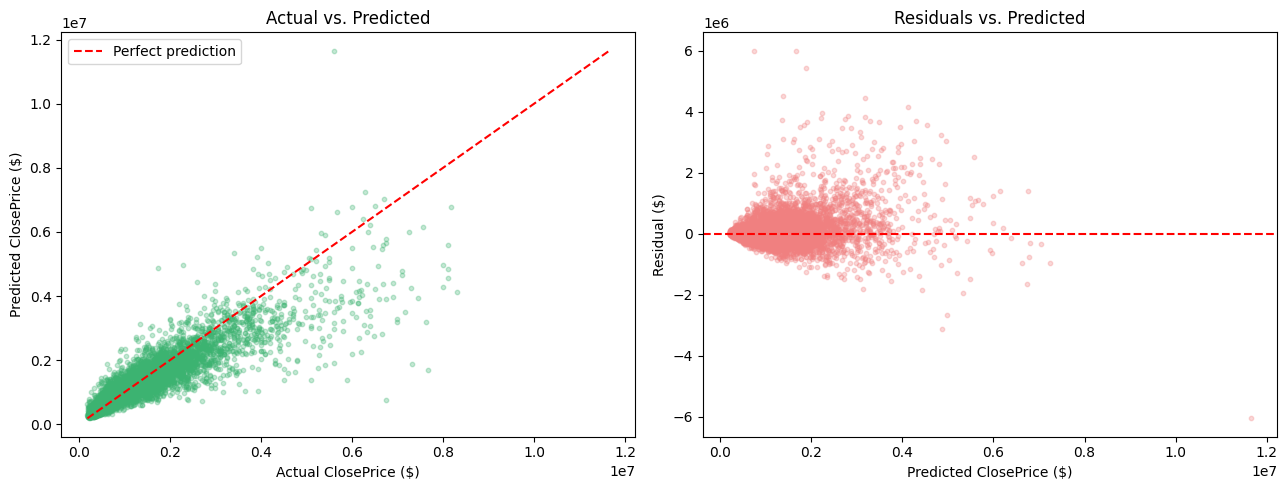

In [43]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# Results from Notebook 3
base = [["Linear Regression v1 (Test)", 0.803955, 423696.58, 216334.04]]
results = pd.DataFrame(base, columns=["Model", "R2", "RMSE", "MAE"])


def predict_model(x_train, y_train, x_eval, actual_close, name, plot=True):

  model = LinearRegression()
  model.fit(x_train, np.log(y_train))

  pred_dollars = np.exp(model.predict(x_eval))
  actual_dollars = np.asarray(actual_close)

  r2 = r2_score(actual_dollars, pred_dollars)
  rmse = np.sqrt(mean_squared_error(actual_dollars, pred_dollars))
  mae = mean_absolute_error(actual_dollars, pred_dollars)

  print(f"R2: {r2}")
  print(f"RMSE: ${round(rmse, 2)}")
  print(f"MAE: ${round(mae, 2)}")

  residuals = actual_close - pred_dollars

  fig, axes = plt.subplots(1, 2, figsize=(13, 5))

  if plot:
    # Actual vs. predicted
    axes[0].scatter(actual_close, pred_dollars, alpha = 0.3, s = 10, color = "mediumseagreen")
    lims = [min(actual_close.min(), pred_dollars.min()), max(actual_close.max(), pred_dollars.max())]

    axes[0].plot(lims, lims, "r--", label="Perfect prediction")
    axes[0].set_xlabel("Actual ClosePrice ($)")
    axes[0].set_ylabel("Predicted ClosePrice ($)")
    axes[0].set_title("Actual vs. Predicted")
    axes[0].legend()

    # Residuals vs. predicted, with a horizontal line at zero
    axes[1].scatter(pred_dollars, residuals, alpha = 0.3, s = 10, color = 'lightcoral')

    axes[1].axhline(0, color="r", linestyle="--")
    axes[1].set_xlabel("Predicted ClosePrice ($)")
    axes[1].set_ylabel("Residual ($)")
    axes[1].set_title("Residuals vs. Predicted")

    plt.tight_layout()
    plt.show()
  return [name, r2, round(rmse, 2), round(mae, 2)]


baseline = predict_model(x_train_model, actual_train_vals, x_valid_model, actual_valid_vals, "Linear Regression v2")

results.loc[len(results)] = baseline

In [44]:
results

,Model,R2,RMSE,MAE
0,Linear Regression v1 (Test),0.803955,423696.58,216334.04
1,Linear Regression v2,0.787236,428635.89,220873.54


R2: 0.7894607473045762
RMSE: $426389.48
MAE: $219549.57


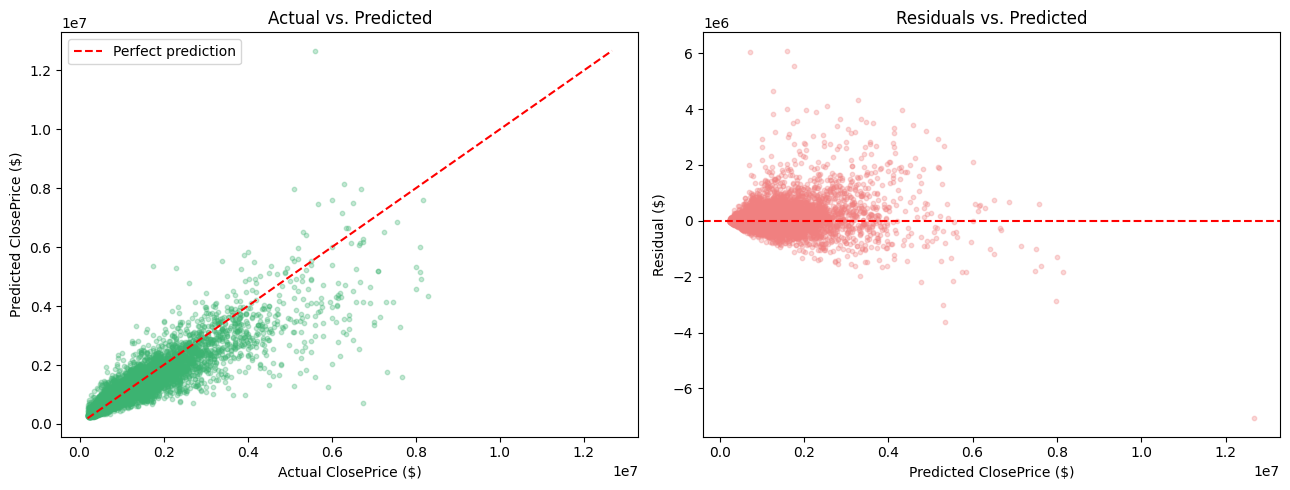

In [45]:
livingarea_mean = x_train_model["logLivingArea"].mean()
lotsize_mean = x_train_model["logLotSizeSquareFeet"].mean()
citypricelevel_mean = x_train_model["CityPriceLevel"].mean()

def add_interaction(df):
  df = df.copy()
  df["LivingAreaXCityLevel"] = (df["logLivingArea"] - livingarea_mean) * (df["CityPriceLevel"] - citypricelevel_mean)
  df["LotSizeXCityLevel"] = (df["logLotSizeSquareFeet"] - lotsize_mean) * (df["CityPriceLevel"] - citypricelevel_mean)
  return df

x_train_int = add_interaction(x_train_model)
x_valid_int = add_interaction(x_valid_model)
x_test_int = add_interaction(x_test_model)

results.loc[len(results)] = predict_model(x_train_int, actual_train_vals, x_valid_int, actual_valid_vals, "Linear Regression v2 w/ int.")

R2: 0.7881958676335268
RMSE: $440396.52
MAE: $230725.22


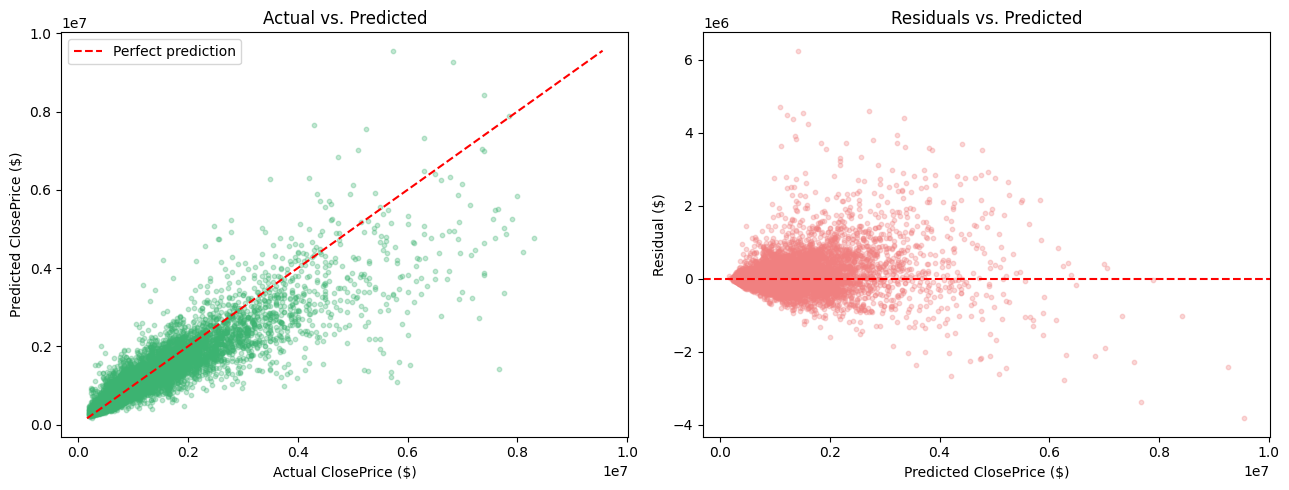

,Model,R2,RMSE,MAE
0,Linear Regression v1 (Test),0.803955,423696.58,216334.04
1,Linear Regression v2,0.787236,428635.89,220873.54
2,Linear Regression v2 w/ int.,0.789461,426389.48,219549.57
3,Linear Regression v2 w/ int. (Test),0.788196,440396.52,230725.22


In [46]:
results.loc[len(results)] = predict_model(x_train_int, actual_train_vals, x_test_int, actual_test_vals, "Linear Regression v2 w/ int. (Test)")

display(results)

# Decision Tree

Using Decision Tree on our models.

In [47]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error


def decision_tree(model, x_train, y_train_dollars, x_eval, actual_close, name, plot=True):
  model.fit(x_train, np.log(y_train_dollars))
  pred_dollars = np.exp(model.predict(x_eval))
  actual_dollars = np.asarray(actual_close)

  r2 = r2_score(actual_dollars, pred_dollars)
  rmse = np.sqrt(mean_squared_error(actual_dollars, pred_dollars))
  mae = mean_absolute_error(actual_dollars, pred_dollars)

  if plot:
    print(f"R2: {r2:.4f}")
    print(f"RMSE: ${rmse:,.2f}")
    print(f"MAE: ${mae:,.2f}")

    residuals = actual_dollars - pred_dollars
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))

    axes[0].scatter(actual_dollars, pred_dollars, alpha=0.3, s=10, color="mediumseagreen")
    lims = [min(actual_dollars.min(), pred_dollars.min()), max(actual_dollars.max(), pred_dollars.max())]
    axes[0].plot(lims, lims, "r--", label="Perfect prediction")
    axes[0].set_xlabel("Actual ClosePrice ($)")
    axes[0].set_ylabel("Predicted ClosePrice ($)")
    axes[0].set_title("Actual vs. Predicted")
    axes[0].legend()

    axes[1].scatter(pred_dollars, residuals, alpha=0.3, s=10, color="lightcoral")
    axes[1].axhline(0, color="r", linestyle="--")
    axes[1].set_xlabel("Predicted ClosePrice ($)")
    axes[1].set_ylabel("Residual ($)")
    axes[1].set_title("Residuals vs. Predicted")

    plt.tight_layout()
    plt.show()

  return [name, r2, round(rmse, 2), round(mae, 2)]


,max_depth,min_samples_leaf,R2,RMSE,MAE
19,20,20,0.832928,379832.32,193155.59
16,16,20,0.832904,379858.97,193531.55
12,12,5,0.829427,383790.87,197748.20
13,12,20,0.827993,385400.97,196985.36
17,16,50,0.827310,386165.30,195781.10
20,20,50,0.827068,386436.00,196040.11
14,12,50,0.824296,389520.70,198841.48
9,10,5,0.820448,393763.59,205403.03
10,10,20,0.819799,394474.48,205221.09
11,10,50,0.818028,396407.83,205883.88


R2: 0.8329
RMSE: $379,832.32
MAE: $193,155.59


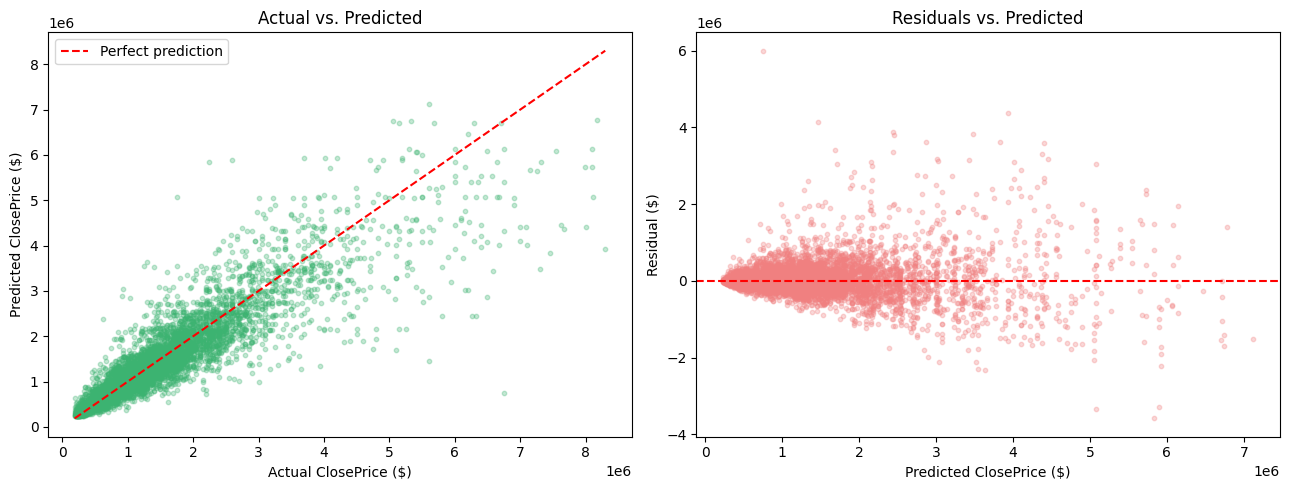

CityPriceLevel           0.582065
LivingAreaXCityLevel     0.203148
logLivingArea            0.147597
Latitude                 0.023894
Longitude                0.021376
LotSizeXCityLevel        0.006004
AgeAtSale                0.005971
logLotSizeSquareFeet     0.005874
BathroomsTotalInteger    0.001739
BedroomsTotal            0.001098
dtype: float64


In [27]:
# tuning
rows = []
for depth in [4, 6, 8, 10, 12, 16, 20]:
  for leaf in [5, 20, 50]:
    tree = DecisionTreeRegressor(max_depth = depth, min_samples_leaf = leaf, random_state = 0)
    res = decision_tree(tree, x_train_int, actual_train_vals, x_valid_int, actual_valid_vals, "tree tuning", plot=False)

    name, r2, rmse, mae = res
    rows.append({"max_depth": depth, "min_samples_leaf": leaf, "R2": r2, "RMSE": rmse, "MAE": mae})

tuning = pd.DataFrame(rows).sort_values("RMSE")
display(tuning.head(10))

# best setting
best = tuning.iloc[0]
best_tree = DecisionTreeRegressor(max_depth = int(best["max_depth"]), min_samples_leaf = int(best["min_samples_leaf"]), random_state=0)
tree_result = decision_tree(best_tree, x_train_int, actual_train_vals, x_valid_int, actual_valid_vals, "Best Tree Result")

importances = pd.Series(best_tree.feature_importances_, index = x_train_int.columns)
print(importances.sort_values(ascending=False).head(10))

Choosing to use `max_depth=12` and `min_samples_leaf=20`. Most likely the safest tree that prevents overfitting data.

Sanity check below.

R2: 0.8551
RMSE: $355,942.16
MAE: $180,614.21


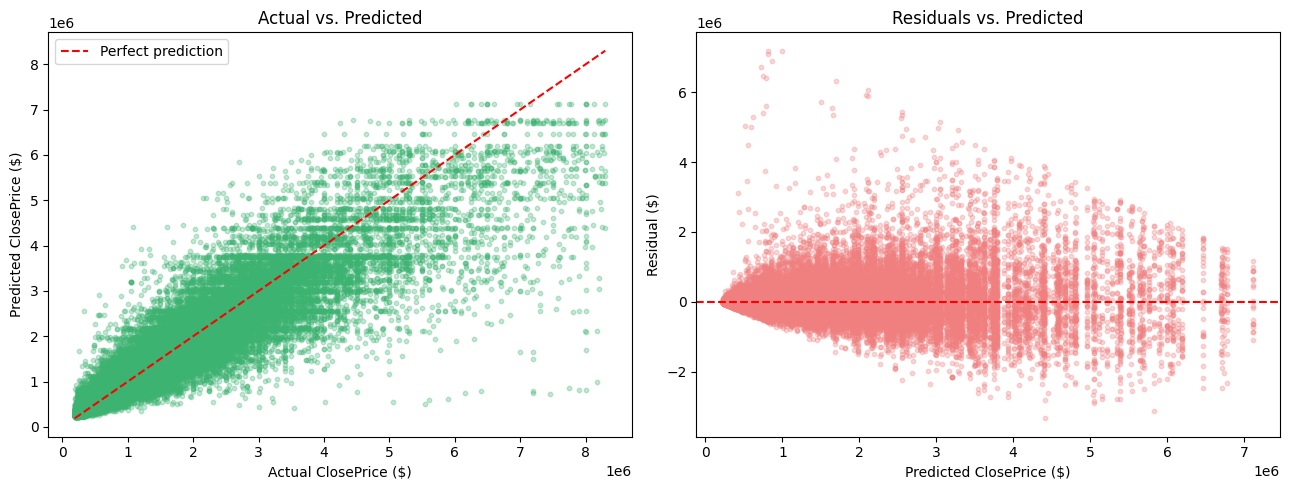

In [28]:
tree = DecisionTreeRegressor(max_depth=12, min_samples_leaf=20, random_state=0)
train_res = decision_tree(tree, x_train_int, actual_train_vals, x_train_int, actual_train_vals, "train check", plot=True)

R2: 0.8207
RMSE: $405,194.69
MAE: $206,569.33


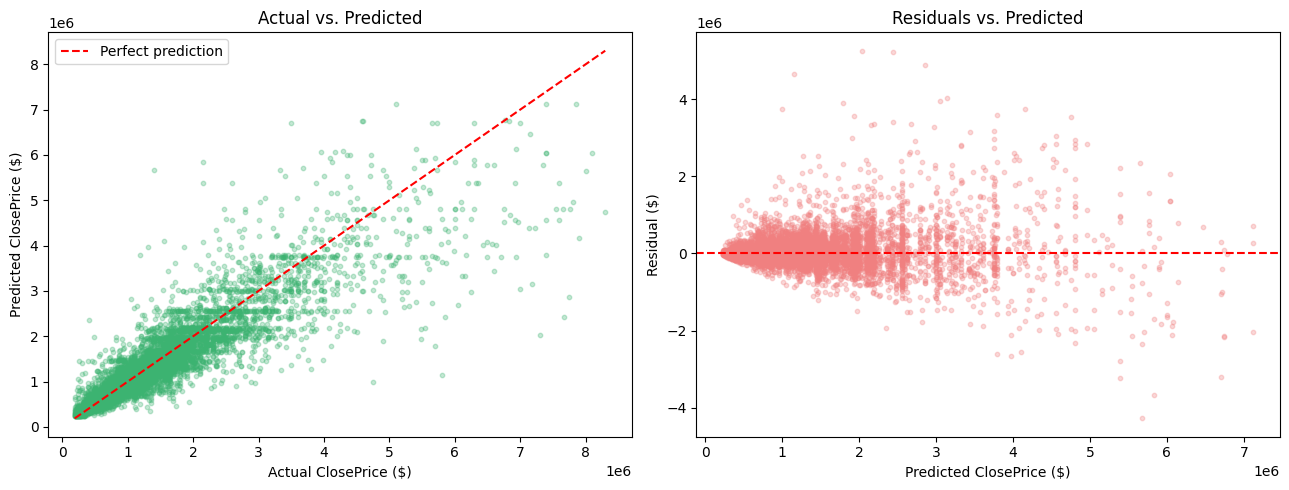

,Model,R2,RMSE,MAE
0,Linear Regression v1 (Test),0.803955,423696.58,216334.04
1,Linear Regression v2,0.787236,428635.89,220873.54
2,Linear Regression v2 w/ int.,0.789461,426389.48,219549.57
3,Linear Regression v2 w/ int. (Test),0.788196,440396.52,230725.22
4,"Decision Tree d=12, leaf=20 (Test)",0.820703,405194.69,206569.33


In [48]:
tree = DecisionTreeRegressor(max_depth=12, min_samples_leaf=20, random_state=0)
test_res = decision_tree(tree, x_train_int, actual_train_vals, x_test_int, actual_test_vals, "Decision Tree d=12, leaf=20 (Test)", plot=True)

results.loc[len(results)] = test_res

display(results)

# Random Forest

In [30]:
from sklearn.ensemble import RandomForestRegressor

def random_forest(model, x_train, y_train_dollars, x_eval, actual_close, name, plot=True):
  model.fit(x_train, np.log(y_train_dollars))
  pred_dollars = np.exp(model.predict(x_eval))
  actual_dollars = np.asarray(actual_close)

  r2   = r2_score(actual_dollars, pred_dollars)
  rmse = np.sqrt(mean_squared_error(actual_dollars, pred_dollars))
  mae  = mean_absolute_error(actual_dollars, pred_dollars)

  if plot:
    print(f"{name}")
    print(f"R2: {r2:.4f}")
    print(f"RMSE: ${rmse:,.2f}")
    print(f"MAE: ${mae:,.2f}")

    residuals = actual_dollars - pred_dollars
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))

    axes[0].scatter(actual_dollars, pred_dollars, alpha=0.3, s=10, color="mediumseagreen")
    lims = [min(actual_dollars.min(), pred_dollars.min()),
            max(actual_dollars.max(), pred_dollars.max())]
    axes[0].plot(lims, lims, "r--", label="Perfect prediction")
    axes[0].set_xlabel("Actual ClosePrice ($)")
    axes[0].set_ylabel("Predicted ClosePrice ($)")
    axes[0].set_title("Actual vs. Predicted")
    axes[0].legend()

    axes[1].scatter(pred_dollars, residuals, alpha=0.3, s=10, color="lightcoral")
    axes[1].axhline(0, color="r", linestyle="--")
    axes[1].set_xlabel("Predicted ClosePrice ($)")
    axes[1].set_ylabel("Residual ($)")
    axes[1].set_title("Residuals vs. Predicted")

    plt.tight_layout()
    plt.show()

  return [name, r2, rmse, mae]

,name,R2,RMSE,MAE
8,RF depth=36 leaf=5,0.863827,342914.424026,168910.232156
4,RF depth=28 leaf=5,0.863798,342951.076480,169061.892010
0,RF depth=20 leaf=5,0.862685,344349.589129,169246.059861
1,RF depth=20 leaf=10,0.857577,350695.432380,173243.440025
5,RF depth=28 leaf=10,0.857522,350763.333489,173299.195431
9,RF depth=36 leaf=10,0.857376,350942.166708,173182.270125
2,RF depth=20 leaf=20,0.849557,360433.721740,178912.300147
10,RF depth=36 leaf=20,0.848943,361169.074286,179019.314995
6,RF depth=28 leaf=20,0.848884,361240.002661,178992.345596
11,RF depth=36 leaf=50,0.836263,376022.337061,187965.570150


Random forest (interactions)
R2: 0.8638
RMSE: $342,914.42
MAE: $168,910.23


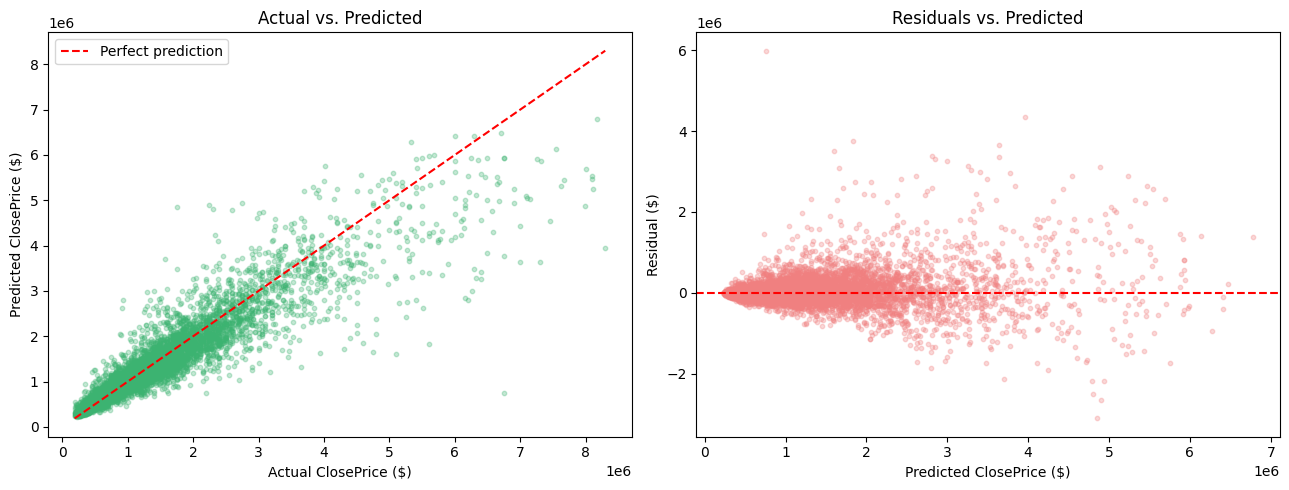

['Random forest (interactions)', 0.8638268052843101, np.float64(342914.42402608827), 168910.2321560157]
CityPriceLevel           0.448801
LivingAreaXCityLevel     0.184875
logLivingArea            0.175332
BathroomsTotalInteger    0.062675
Longitude                0.036615
Latitude                 0.032702
LotSizeXCityLevel        0.015110
logLotSizeSquareFeet     0.014005
BedroomsTotal            0.013179
AgeAtSale                0.011582
dtype: float64


In [31]:
# Tuning
rows = []
for depth in [20, 28, 36]:
  for leaf in [5, 10, 20, 50]:
    rf = RandomForestRegressor(n_estimators = 200, max_depth = depth, min_samples_leaf = leaf, max_features = 0.5, n_jobs = -1, random_state = 0)
    res = random_forest(rf, x_train_int, actual_train_vals, x_valid_int, actual_valid_vals, f"RF depth={depth} leaf={leaf}", plot=False)
    rows.append(res)

tuning = pd.DataFrame(rows, columns=["name", "R2", "RMSE", "MAE"]).sort_values("RMSE")
display(tuning)

# Best setting
best_name = tuning.iloc[0]["name"]
best_depth = int(best_name.split("depth=")[1].split(" ")[0])
best_leaf = int(best_name.split("leaf=")[1])

best_rf = RandomForestRegressor(n_estimators = 200, max_depth = best_depth, min_samples_leaf = best_leaf, max_features = 0.5, n_jobs = -1, random_state=0)
rf_result = random_forest(best_rf, x_train_int, actual_train_vals, x_valid_int, actual_valid_vals, "Random forest (interactions)")
print(rf_result)

importances = pd.Series(best_rf.feature_importances_, index = x_train_int.columns)
print(importances.sort_values(ascending=False).head(10))

RF train check
R2: 0.8666
RMSE: $339,370.44
MAE: $167,330.00


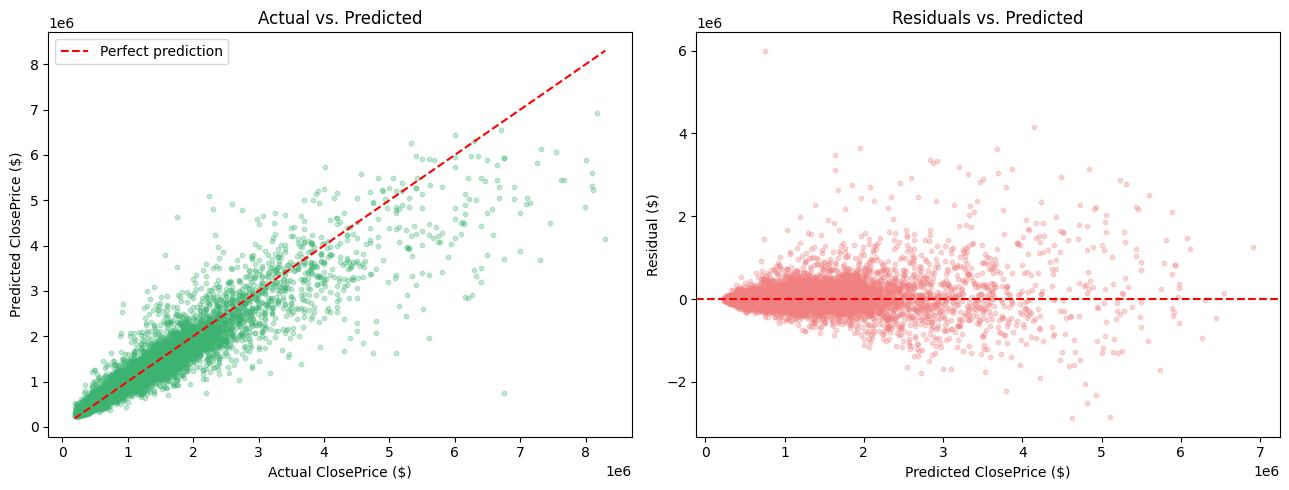

['RF train check',
 0.8666269344914173,
 np.float64(339370.4362345179),
 167329.99837474758]

In [51]:
chosen_rf = RandomForestRegressor(n_estimators=200, max_depth=20, min_samples_leaf=3, max_features=0.5, n_jobs=-1, random_state=0)

random_forest(chosen_rf, x_train_int, actual_train_vals, x_valid_int, actual_valid_vals, "RF train check", plot=True)

RF train check
R2: 0.8667
RMSE: $339,316.53
MAE: $166,991.28


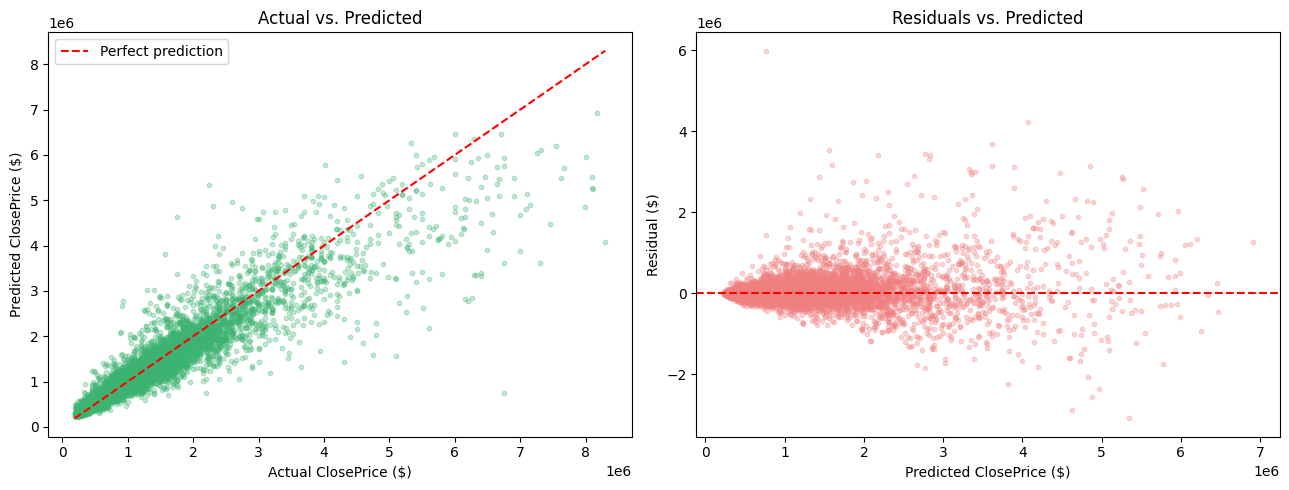

['RF train check',
 0.8666692992960607,
 np.float64(339316.5329067707),
 166991.28224222639]

In [53]:
chosen_rf_2 = RandomForestRegressor(n_estimators=200, max_depth=20, min_samples_leaf=2, max_features=0.5, n_jobs=-1, random_state=0)

random_forest(chosen_rf_2, x_train_int, actual_train_vals, x_valid_int, actual_valid_vals, "RF train check", plot=True)

Depth of 20 performed well with higher depths performing marginally better (12 and 8 were tested before and 20 performed best). Smaller leaves perform better across all depths.

RF Depth=20 Leaf=2 (Test)
R2: 0.8636
RMSE: $353,433.31
MAE: $173,928.46


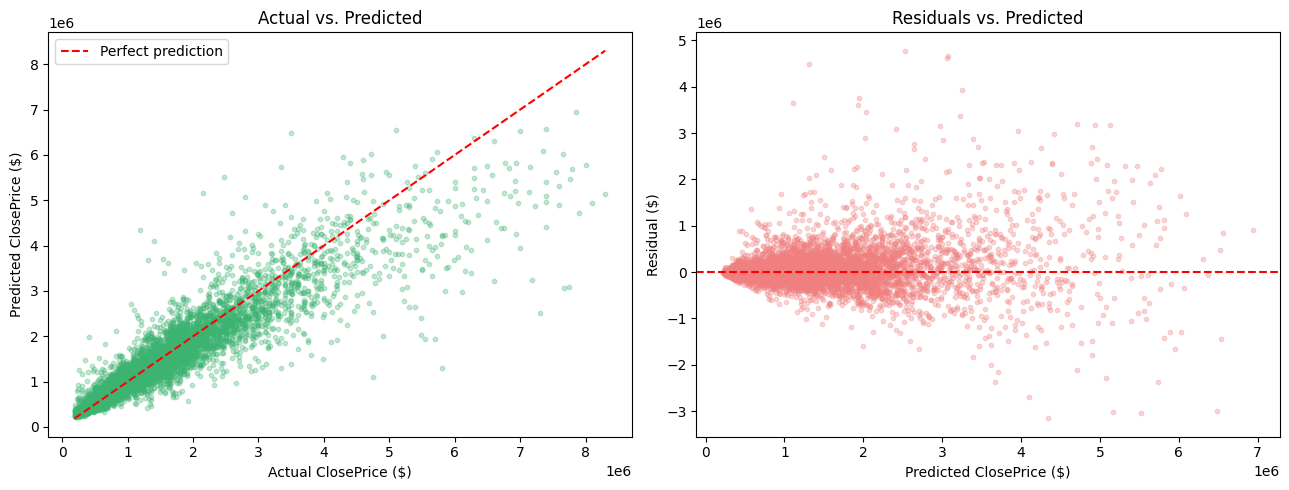

,Model,R2,RMSE,MAE
0,Linear Regression v1 (Test),0.803955,423696.580000,216334.040000
1,Linear Regression v2,0.787236,428635.890000,220873.540000
2,Linear Regression v2 w/ int.,0.789461,426389.480000,219549.570000
3,Linear Regression v2 w/ int. (Test),0.788196,440396.520000,230725.220000
4,"Decision Tree d=12, leaf=20 (Test)",0.820703,405194.690000,206569.330000
5,RF Depth=20 Leaf=2 (Test),0.863585,353433.312518,173928.457359


In [54]:
test_rf = RandomForestRegressor(n_estimators=200, max_depth=20, min_samples_leaf=2, max_features=0.5, n_jobs=-1, random_state=0)

results.loc[len(results)] = random_forest(chosen_rf_2, x_train_int, actual_train_vals, x_test_int, actual_test_vals, "RF Depth=20 Leaf=2 (Test)", plot=True)
display(results)

# Model Behavior
The test datasets are tested once per model.

## Decision Tree

Strengths:
*   Performs better across all metrics than Linear Regression

Weaknesses:
*   Overfitting is a worry

## Random Forest

Strengths:
*   Strongest predictive model of all three

Weaknesses:
*   Very long runtime (30 mins for various tuning)

## Across Both Models
*   Under predicting more expensive homes on average

